In [ ]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Generate the dataset
np.random.seed(42)
n = 5000

temperature = np.random.normal(25, 5, n)
humidity = np.random.normal(60, 15, n)
rainfall = np.random.exponential(50, n)
soil_ph = np.random.normal(6.5, 1, n)
plant_age = np.random.randint(10, 120, n)

# Create disease_score (SUSPICIOUS FEATURE)
disease_score = 0.3 * temperature + 0.5 * humidity + 0.1 * rainfall - 0.2 * soil_ph
target = (disease_score > np.percentile(disease_score, 55)).astype(int)

df = pd.DataFrame({
    'temperature': temperature,
    'humidity': humidity,
    'rainfall': rainfall,
    'soil_ph': soil_ph,
    'plant_age': plant_age,
    'disease_score': disease_score,
    'target': target
})

# Save the dataset
df.to_csv('group3_dataset.csv', index=False)

# DATA INSPECTION
print("=" * 50)
print("DATA OVERVIEW")
print("=" * 50)
print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nData Types and Missing Values:")
print(df.info())
print("\nStatistical Summary:")
print(df.describe())

DATA OVERVIEW
Shape: (5000, 7)

First 5 rows:
   temperature   humidity   rainfall   soil_ph  plant_age  disease_score  \
0    27.483571  53.643605  19.375501  9.235960         44      35.157232   
1    24.308678  53.198788   5.436041  7.068770         76      33.021848   
2    28.238443  33.065352   3.725809  5.870114        104      24.202767   
3    32.615149  55.048647   4.951032  6.847916        115      36.434388   
4    23.829233  70.992436  43.717791  8.280639         16      45.360639   

   target  
0       0  
1       0  
2       0  
3       0  
4       1  

Data Types and Missing Values:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   temperature    5000 non-null   float64
 1   humidity       5000 non-null   float64
 2   rainfall       5000 non-null   float64
 3   soil_ph        5000 non-null   float64
 4   plant_age      5000 non-null 

In [22]:
# Quick overview
print(f"Total rows: {len(df)}")
print(f"Total columns: {len(df.columns)}")
print(f"Column names: {df.columns.tolist()}")
print("\nFirst 100 rows:")
print(df.head(100))

Total rows: 5000
Total columns: 7
Column names: ['temperature', 'humidity', 'rainfall', 'soil_ph', 'plant_age', 'disease_score', 'target']

First 100 rows:
    temperature   humidity    rainfall   soil_ph  plant_age  disease_score  \
0     27.483571  53.643605   19.375501  9.235960         44      35.157232   
1     24.308678  53.198788    5.436041  7.068770         76      33.021848   
2     28.238443  33.065352    3.725809  5.870114        104      24.202767   
3     32.615149  55.048647    4.951032  6.847916        115      36.434388   
4     23.829233  70.992436   43.717791  8.280639         16      45.360639   
..          ...        ...         ...       ...        ...            ...   
95    17.682425  54.811210   47.503151  5.724517         35      36.315744   
96    26.480601  73.337307   71.705980  6.624868         51      50.458459   
97    26.305276  43.173733   39.450207  5.717459         25      32.279979   
98    25.025567  48.497039   49.393412  6.186048         31     

In [23]:
# METHOD 1: Basic Info
print("=" * 50)
print("BASIC ATTRIBUTE INFO")
print("=" * 50)
print(df.info())

BASIC ATTRIBUTE INFO
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   temperature    5000 non-null   float64
 1   humidity       5000 non-null   float64
 2   rainfall       5000 non-null   float64
 3   soil_ph        5000 non-null   float64
 4   plant_age      5000 non-null   int32  
 5   disease_score  5000 non-null   float64
 6   target         5000 non-null   int64  
dtypes: float64(5), int32(1), int64(1)
memory usage: 254.0 KB
None


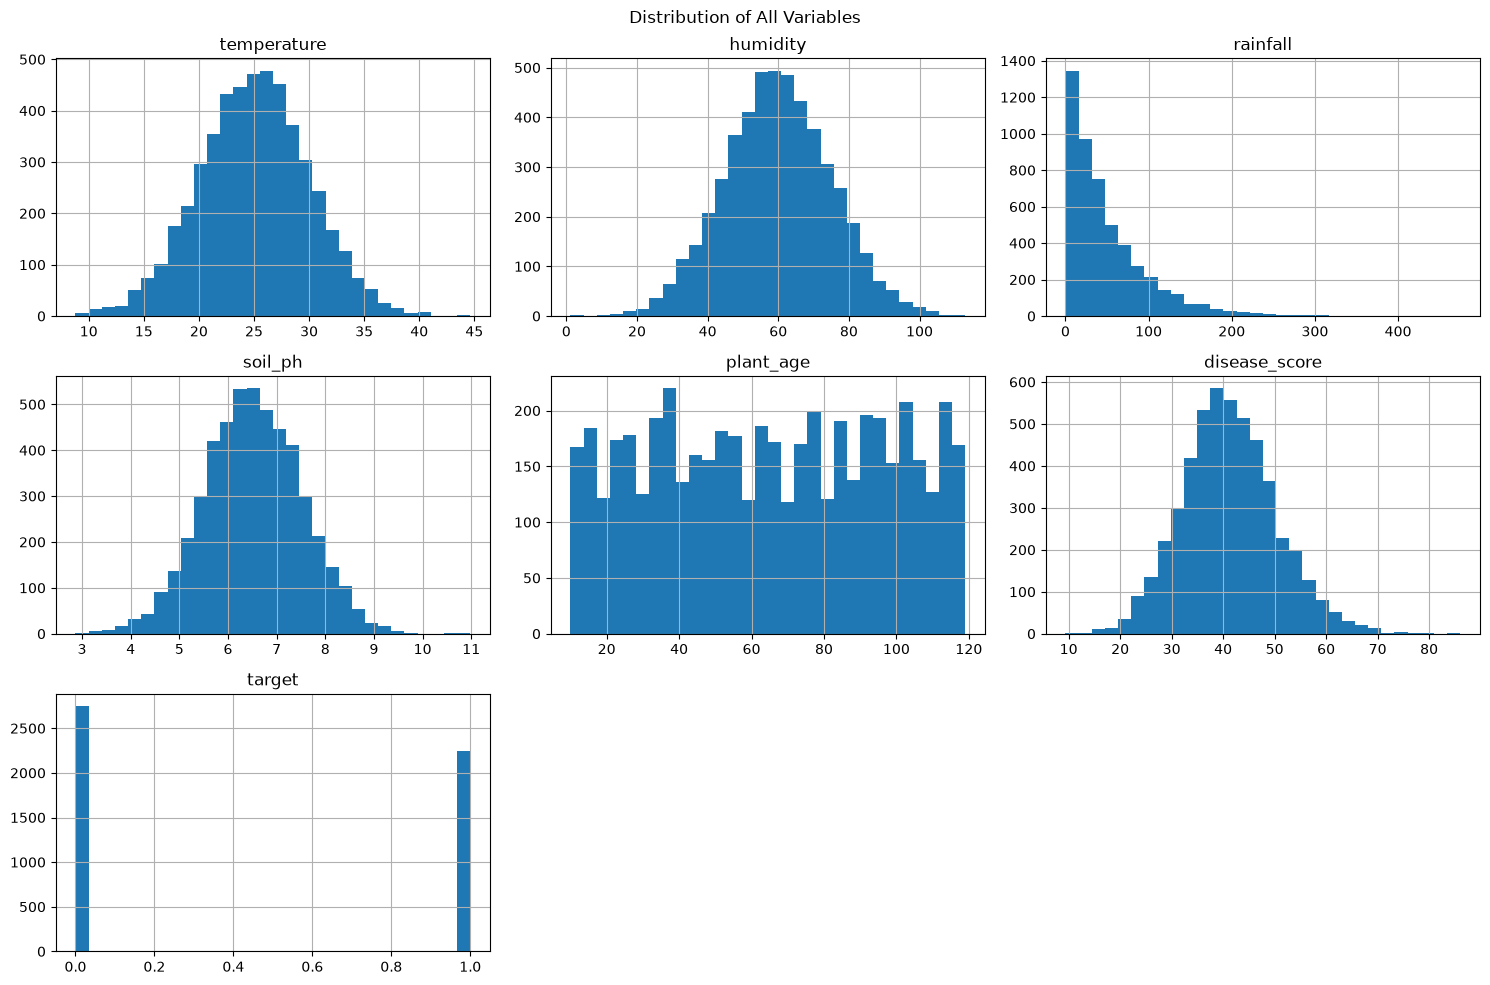

In [24]:
df.hist(figsize=(15,10), bins=30)
plt.suptitle("Distribution of All Variables")
plt.tight_layout()
plt.show()

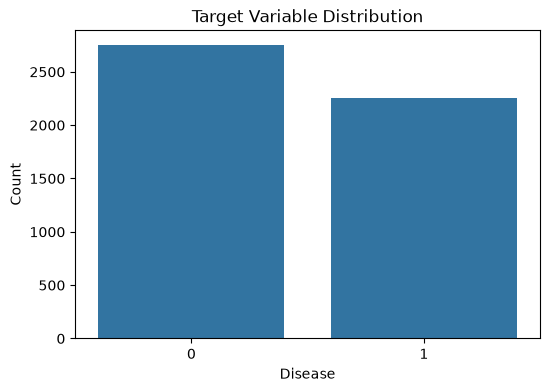

target
0    2750
1    2250
Name: count, dtype: int64


In [25]:
plt.figure(figsize=(6,4))
sns.countplot(x='target', data=df)
plt.title("Target Variable Distribution")
plt.xlabel("Disease")
plt.ylabel("Count")
plt.show()

print(df['target'].value_counts())

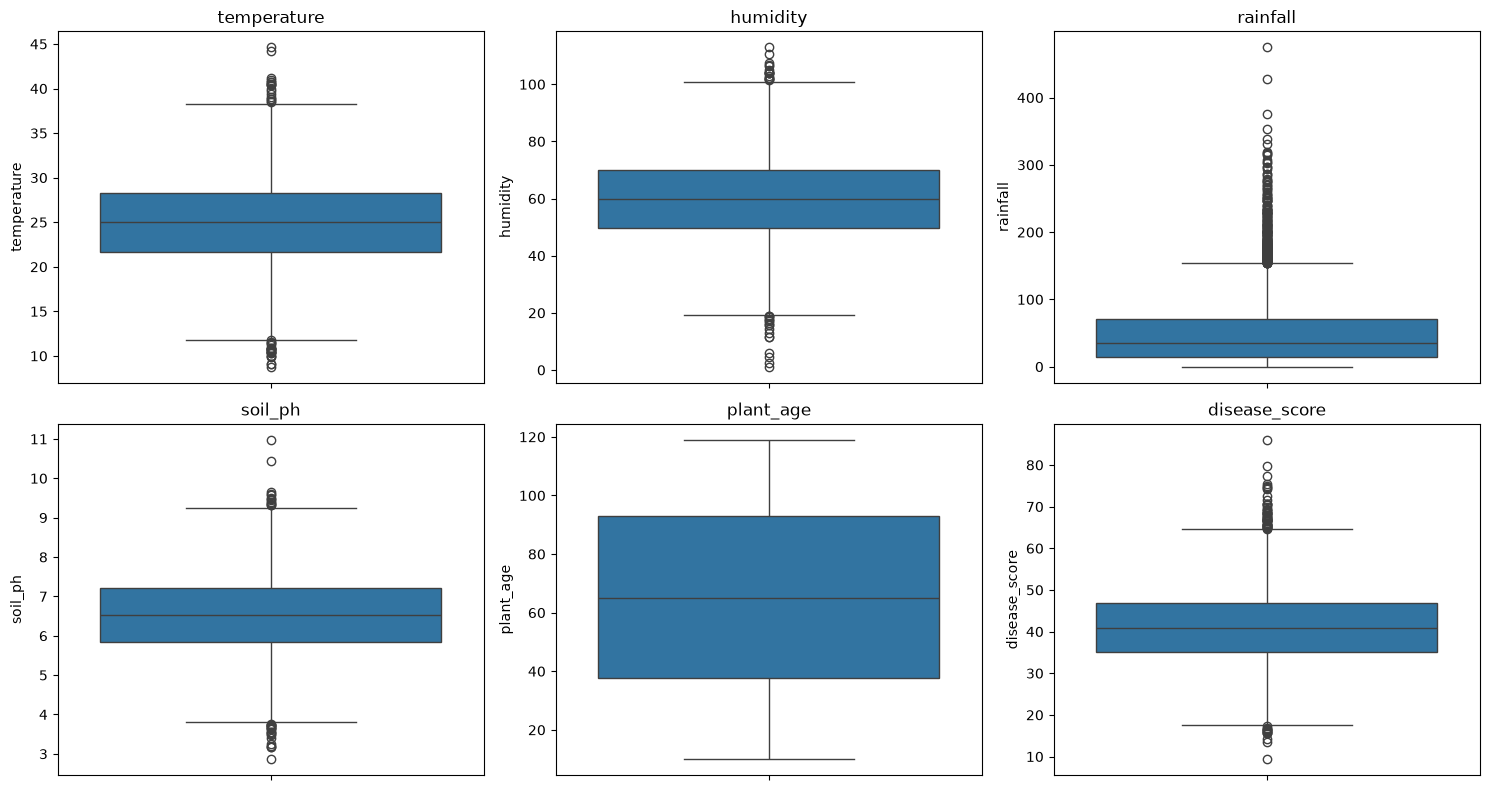

In [ ]:
#outliers
plt.figure(figsize=(15,8))

for i, column in enumerate(df.columns[:-1], 1):
    plt.subplot(2,3,i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

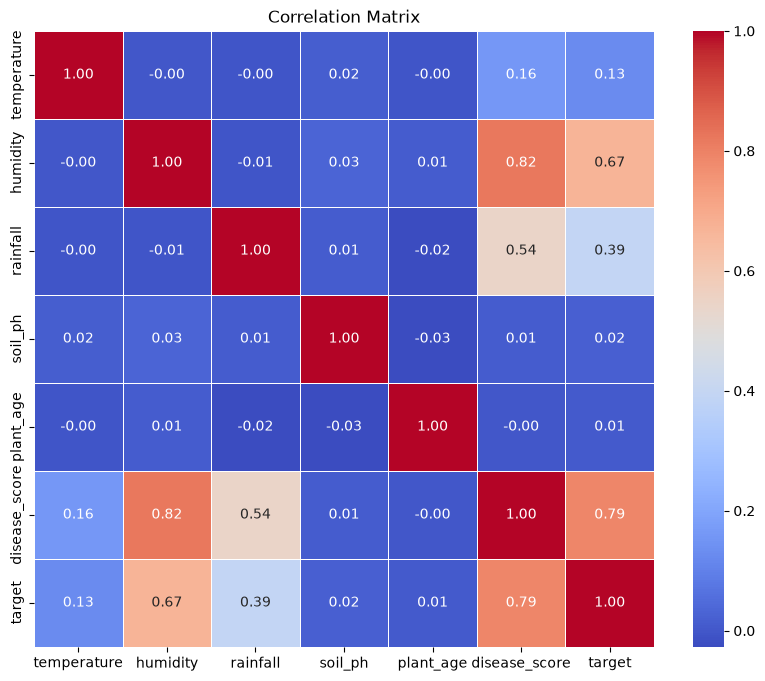

In [28]:
# Question 3: Correlation Matrix
# 
plt.figure(figsize=(10,8))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

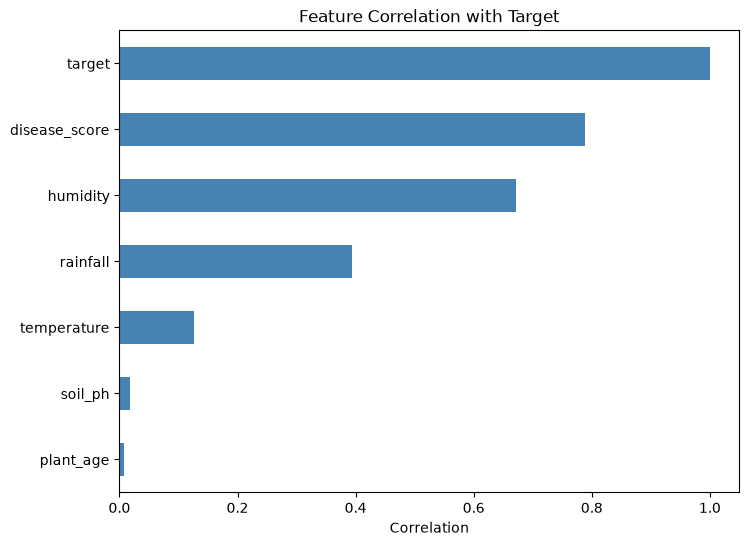

In [31]:
plt.figure(figsize=(8,6))

corr['target'].sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title("Feature Correlation with Target")
plt.xlabel("Correlation")
plt.show()

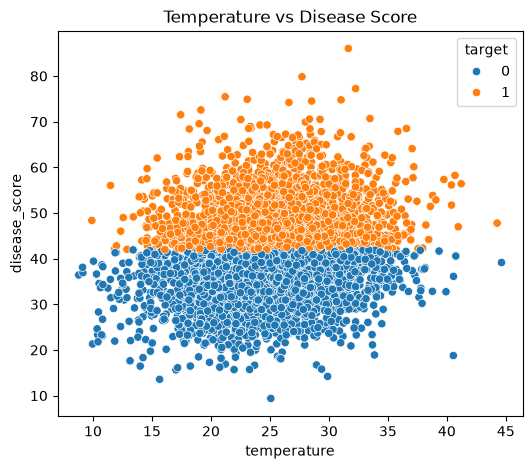

In [35]:
# Scatter Plots
# Relationship between Temperature and Disease Score
plt.figure(figsize=(6,5))

sns.scatterplot(
    x='temperature',
    y='disease_score',
    hue='target',
    data=df
)

plt.title("Temperature vs Disease Score")
plt.show()

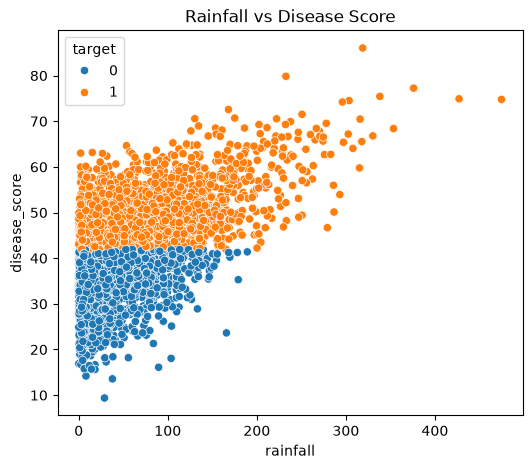

In [36]:
# Scatter Plots
# Rainfall vs Disease Score
plt.figure(figsize=(6,5))

sns.scatterplot(
    x='rainfall',
    y='disease_score',
    hue='target',
    data=df
)

plt.title("Rainfall vs Disease Score")
plt.show()

In [40]:
# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Features and Target
X = df.drop('target', axis=1)
y = df['target']

In [43]:
# Split the Dataset
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

# Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training samples: (4000, 6)
Testing samples: (1000, 6)


In [44]:
# Logistic Regression : Train Model 1 
lr = LogisticRegression(random_state=42)

lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

print("="*50)
print("LOGISTIC REGRESSION")
print("="*50)

print("Accuracy:",
      accuracy_score(y_test, lr_pred))

print("\nClassification Report")
print(classification_report(y_test, lr_pred))

LOGISTIC REGRESSION
Accuracy: 0.996

Classification Report
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       550
           1       1.00      0.99      1.00       450

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [45]:
# Decision Tree : Train Model 2
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print("="*50)
print("DECISION TREE")
print("="*50)

print("Accuracy:",
      accuracy_score(y_test, dt_pred))

print("\nClassification Report")
print(classification_report(y_test, dt_pred))

DECISION TREE
Accuracy: 1.0

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       550
           1       1.00      1.00      1.00       450

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [46]:
# Random Forest : Train Model 3
rf = RandomForestClassifier(
    random_state=42,
    n_estimators=100
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("="*50)
print("RANDOM FOREST")
print("="*50)

print("Accuracy:",
      accuracy_score(y_test, rf_pred))

print("\nClassification Report")
print(classification_report(y_test, rf_pred))

RANDOM FOREST
Accuracy: 1.0

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       550
           1       1.00      1.00      1.00       450

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [ ]:
# Comparing the Models 

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ]
})

print(results)

# Visualize Model Performance
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="Accuracy",
    y="Model",
    palette="viridis"
)

plt.title("Comparison of Classification Models")
plt.xlim(0,1)

plt.show()

                 Model  Accuracy
0  Logistic Regression     0.996
1        Decision Tree     1.000
2        Random Forest     1.000


C:\Users\USER\AppData\Local\Temp\ipykernel_1536\2620063015.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


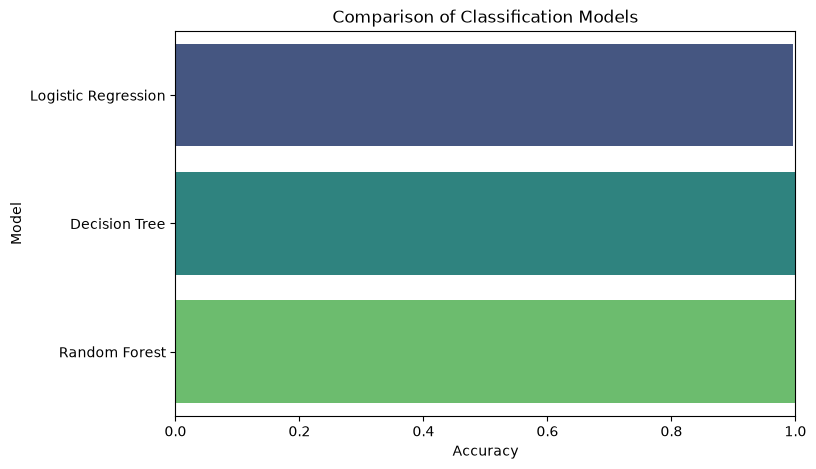

In [48]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="Accuracy",
    y="Model",
    palette="viridis"
)

plt.title("Comparison of Classification Models")
plt.xlim(0,1)

plt.show()

In [50]:
# 5: Record Training and Test Results
# Training Accuracy
lr_train_pred = lr.predict(X_train_scaled)
lr_train_acc = accuracy_score(y_train, lr_train_pred)

# Test Accuracy
lr_test_acc = accuracy_score(y_test, lr_pred)

print("Logistic Regression")
print("Training Accuracy:", lr_train_acc)
print("Test Accuracy:", lr_test_acc)


# Training Accuracy
dt_train_pred = dt.predict(X_train)
dt_train_acc = accuracy_score(y_train, dt_train_pred)

# Test Accuracy
dt_test_acc = accuracy_score(y_test, dt_pred)

print("\nDecision Tree")
print("Training Accuracy:", dt_train_acc)
print("Test Accuracy:", dt_test_acc)

# Training Accuracy
rf_train_pred = rf.predict(X_train)
rf_train_acc = accuracy_score(y_train, rf_train_pred)

# Test Accuracy
rf_test_acc = accuracy_score(y_test, rf_pred)

print("\nRandom Forest")
print("Training Accuracy:", rf_train_acc)
print("Test Accuracy:", rf_test_acc)

Logistic Regression
Training Accuracy: 0.9965
Test Accuracy: 0.996

Decision Tree
Training Accuracy: 1.0
Test Accuracy: 1.0

Random Forest
Training Accuracy: 1.0
Test Accuracy: 1.0


In [51]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Training Accuracy": [
        lr_train_acc,
        dt_train_acc,
        rf_train_acc
    ],
    "Test Accuracy": [
        lr_test_acc,
        dt_test_acc,
        rf_test_acc
    ]
})

print(results)

                 Model  Training Accuracy  Test Accuracy
0  Logistic Regression             0.9965          0.996
1        Decision Tree             1.0000          1.000
2        Random Forest             1.0000          1.000


In [53]:
# question 6. Investigate whether the performance is realistic.  
disease_score = (
    0.3 * temperature
    + 0.5 * humidity
    + 0.1 * rainfall
    - 0.2 * soil_ph
)

target = (
    disease_score >
    np.percentile(disease_score,55)
).astype(int)

In [55]:
# 7. Investigate whether any feature is mathematically or logically derived from other predictors.
temperature = np.random.normal(25, 5, n)
humidity = np.random.normal(60, 15, n)
rainfall = np.random.exponential(50, n)
soil_ph = np.random.normal(6.5, 1, n)
plant_age = np.random.randint(10, 120, n)

# Create disease_score
disease_score = (
    0.3 * temperature +
    0.5 * humidity +
    0.1 * rainfall -
    0.2 * soil_ph
)

target = (
    disease_score >
    np.percentile(disease_score, 55)
).astype(int)

disease_score = (
    0.3 * temperature +
    0.5 * humidity +
    0.1 * rainfall -
    0.2 * soil_ph
)

In [56]:
# 8. Test the effect of removing suspicious or redundant features. 
# Remove the suspicious feature
X_new = df.drop(columns=['target', 'disease_score'])
y = df['target']

print(X_new.head())

   temperature   humidity   rainfall   soil_ph  plant_age
0    27.483571  53.643605  19.375501  9.235960         44
1    24.308678  53.198788   5.436041  7.068770         76
2    28.238443  33.065352   3.725809  5.870114        104
3    32.615149  55.048647   4.951032  6.847916        115
4    23.829233  70.992436  43.717791  8.280639         16


In [57]:
from sklearn.model_selection import train_test_split

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
# Scale the Data (for Logistic Regression)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled_new = scaler.fit_transform(X_train_new)
X_test_scaled_new = scaler.transform(X_test_new)

In [62]:
# Retrain Logistic Regression
lr_new = LogisticRegression(random_state=42)

lr_new.fit(X_train_scaled_new, y_train_new)

lr_train_pred_new = lr_new.predict(X_train_scaled_new)
lr_test_pred_new = lr_new.predict(X_test_scaled_new)

lr_train_acc_new = accuracy_score(y_train_new, lr_train_pred_new)
lr_test_acc_new = accuracy_score(y_test_new, lr_test_pred_new)

# Retrain Decision Tree
dt_new = DecisionTreeClassifier(random_state=42)

dt_new.fit(X_train_new, y_train_new)

dt_train_pred_new = dt_new.predict(X_train_new)
dt_test_pred_new = dt_new.predict(X_test_new)

dt_train_acc_new = accuracy_score(y_train_new, dt_train_pred_new)
dt_test_acc_new = accuracy_score(y_test_new, dt_test_pred_new)

#Retrain Random Forest 
rf_new = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_new.fit(X_train_new, y_train_new)

rf_train_pred_new = rf_new.predict(X_train_new)
rf_test_pred_new = rf_new.predict(X_test_new)

rf_train_acc_new = accuracy_score(y_train_new, rf_train_pred_new)
rf_test_acc_new = accuracy_score(y_test_new, rf_test_pred_new)

In [63]:
# Compare Before and After
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Before Removal": [
        lr_test_acc,
        dt_test_acc,
        rf_test_acc
    ],
    "After Removal": [
        lr_test_acc_new,
        dt_test_acc_new,
        rf_test_acc_new
    ]
})

print(comparison)

                 Model  Before Removal  After Removal
0  Logistic Regression           0.996          0.997
1        Decision Tree           1.000          0.966
2        Random Forest           1.000          0.978


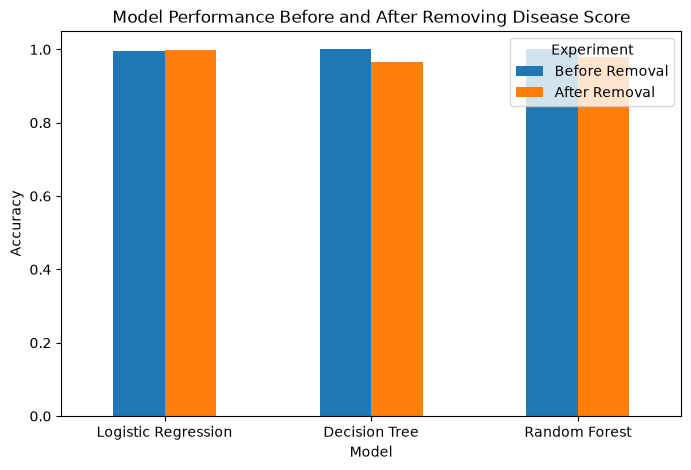

In [64]:
# Visualize the Comparison
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Model Performance Before and After Removing Disease Score")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Experiment")
plt.show()

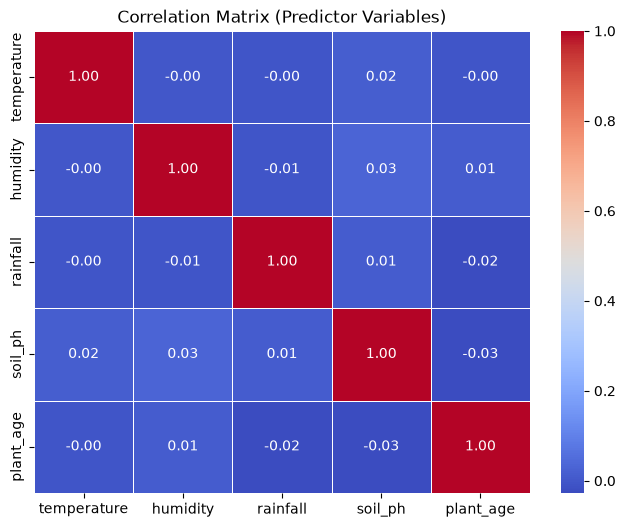

In [65]:
# 9. Investigate feature correlation and multicollinearity. 
# Correlation Matrix (Without disease_score)
# Select only predictor variables
X_corr = df.drop(columns=['target', 'disease_score'])

# Correlation matrix
corr_matrix = X_corr.corr()

# Plot heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix (Predictor Variables)")
plt.show()

In [66]:
# Variance Inflation Factor (VIF) "standard way to measure multicollinearity."
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Predictor variables only
X_vif = df.drop(columns=['target', 'disease_score'])

# Calculate VIF
vif = pd.DataFrame()
vif["Feature"] = X_vif.columns
vif["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

print(vif)

       Feature        VIF
0  temperature  18.903675
1     humidity  13.978203
2     rainfall   1.979445
3      soil_ph  23.355509
4    plant_age   4.922583


In [79]:
# 10.Perform appropriate preprocessing. 
# 10: Perform Appropriate Preprocessing

# 1. Check missing values
print("Missing values before preprocessing:")
print(df.isnull().sum())

# 2. Remove duplicate rows
df = df.drop_duplicates()

# 3. Check the dataset after removing duplicates
print("Dataset shape after removing duplicates:", df.shape)

# 4. Separate features and target
X = df.drop(columns=['disease_score'])
y = df['disease_score']

print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

# 5. Identify numerical and categorical columns
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns

print("\nNumerical features:")
print(list(numerical_features))

print("\nCategorical features:")
print(list(categorical_features))

Missing values before preprocessing:
temperature      0
humidity         0
rainfall         0
soil_ph          0
plant_age        0
disease_score    0
target           0
dtype: int64
Dataset shape after removing duplicates: (5000, 7)
Features:
Index(['temperature', 'humidity', 'rainfall', 'soil_ph', 'plant_age',
       'target'],
      dtype='str')

Target:
disease_score

Numerical features:
['temperature', 'humidity', 'rainfall', 'soil_ph', 'target']

Categorical features:
[]


In [78]:
# 11.Perform cross-validation. 
# Question 11: Cross-Validation